# Ball-by-Ball Data — EDA & Data Cleaning

## Objective

Each row represents a single delivery in an IPL match (season 2008–2026).
This is the most granular dataset in the project.

**In scope:** Structure inspection, column investigation, missing-value analysis, justified cleaning.
**Out of scope:** Cross-file joins, relational schema, aggregated metrics, dashboards.

## 1. Imports and Data Loading

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 60)


In [35]:
DATA_PATH = '../../ball_by_ball_data.csv'

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print(f'Loaded: {df.shape[0]:,} rows x {df.shape[1]} columns')


Loaded: 288,226 rows x 30 columns


## 2. Structure Overview

In [36]:
df.dtypes


season_id            int64
match_id             int64
batter                 str
bowler                 str
non_striker            str
team_batting         int64
team_bowling         int64
over_number          int64
ball_number          int64
batter_runs          int64
extras               int64
total_runs           int64
batsman_type           str
bowler_type            str
player_out             str
fielders_involved      str
is_wicket             bool
is_wide_ball          bool
is_no_ball            bool
is_leg_bye            bool
is_bye                bool
is_penalty            bool
wide_ball_runs       int64
no_ball_runs         int64
leg_bye_runs         int64
bye_runs             int64
penalty_runs         int64
wicket_kind            str
is_super_over         bool
innings              int64
dtype: object

In [37]:
df.head(5)


,season_id,match_id,batter,bowler,non_striker,team_batting,team_bowling,over_number,ball_number,batter_runs,extras,total_runs,batsman_type,bowler_type,player_out,fielders_involved,is_wicket,is_wide_ball,is_no_ball,is_leg_bye,is_bye,is_penalty,wide_ball_runs,no_ball_runs,leg_bye_runs,bye_runs,penalty_runs,wicket_kind,is_super_over,innings
0,2008,335982,SC Ganguly,P Kumar,BB McCullum,6,1,0,0,0,1,1,Left hand Bat,Right arm Medium,NaN,NaN,False,False,False,True,False,False,0,0,1,0,0,NaN,False,1
1,2008,335982,BB McCullum,P Kumar,SC Ganguly,6,1,0,1,0,0,0,Right hand Bat,Right arm Medium,NaN,NaN,False,False,False,False,False,False,0,0,0,0,0,NaN,False,1
2,2008,335982,BB McCullum,P Kumar,SC Ganguly,6,1,0,2,0,1,1,Right hand Bat,Right arm Medium,NaN,NaN,False,True,False,False,False,False,1,0,0,0,0,NaN,False,1
3,2008,335982,BB McCullum,P Kumar,SC Ganguly,6,1,0,3,0,0,0,Right hand Bat,Right arm Medium,NaN,NaN,False,False,False,False,False,False,0,0,0,0,0,NaN,False,1
4,2008,335982,BB McCullum,P Kumar,SC Ganguly,6,1,0,4,0,0,0,Right hand Bat,Right arm Medium,NaN,NaN,False,False,False,False,False,False,0,0,0,0,0,NaN,False,1


In [38]:
df.tail(3)


,season_id,match_id,batter,bowler,non_striker,team_batting,team_bowling,over_number,ball_number,batter_runs,extras,total_runs,batsman_type,bowler_type,player_out,fielders_involved,is_wicket,is_wide_ball,is_no_ball,is_leg_bye,is_bye,is_penalty,wide_ball_runs,no_ball_runs,leg_bye_runs,bye_runs,penalty_runs,wicket_kind,is_super_over,innings
288223,2026,1529286,T Stubbs,JC Archer,Ashutosh Sharma,252,134,18,5,4,0,4,Right hand Bat,Right arm Fast,NaN,NaN,False,False,False,False,False,False,0,0,0,0,0,NaN,False,2
288224,2026,1529286,Ashutosh Sharma,Brijesh Sharma,T Stubbs,252,134,19,0,4,0,4,Right hand Bat,Right arm Medium,NaN,NaN,False,False,False,False,False,False,0,0,0,0,0,NaN,False,2
288225,2026,1529286,Ashutosh Sharma,Brijesh Sharma,T Stubbs,252,134,19,1,0,1,1,Right hand Bat,Right arm Medium,NaN,NaN,False,False,True,False,False,False,0,1,0,0,0,NaN,False,2


In [39]:
null_summary = pd.DataFrame({
    'null_count': df.isnull().sum(),
    'null_pct': (df.isnull().mean() * 100).round(2)
})
null_summary[null_summary['null_count'] > 0]


,null_count,null_pct
batsman_type,239,0.08
bowler_type,339,0.12
player_out,273886,95.02
fielders_involved,273886,95.02
wicket_kind,273886,95.02


In [40]:
df.describe()


,season_id,match_id,team_batting,team_bowling,over_number,ball_number,batter_runs,extras,total_runs,wide_ball_runs,no_ball_runs,leg_bye_runs,bye_runs,penalty_runs,innings
count,288226.000000,2.882260e+05,288226.000000,288226.000000,288226.000000,288226.000000,288226.000000,288226.000000,288226.000000,288226.000000,288226.000000,288226.000000,288226.000000,288226.000000,288226.000000
mean,2017.033165,9.626527e+05,182.616017,181.611912,9.190375,2.628160,1.284638,0.068217,1.352855,0.039531,0.004278,0.019662,0.004712,0.000035,1.482770
std,5.430094,3.901018e+05,274.658815,274.556424,5.680521,1.818354,1.658509,0.342774,1.644513,0.255583,0.068987,0.190444,0.114574,0.013171,0.502508
min,2008.000000,3.359820e+05,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2012.000000,5.483640e+05,3.000000,3.000000,4.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,2017.000000,1.082623e+06,129.000000,129.000000,9.000000,3.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,2022.000000,1.304080e+06,252.000000,252.000000,14.000000,4.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
max,2026.000000,1.529286e+06,1419.000000,1419.000000,19.000000,10.000000,6.000000,7.000000,7.000000,5.000000,5.000000,5.000000,4.000000,5.000000,6.000000


In [41]:
mem_mb = df.memory_usage(deep=True).sum() / 1024**2
print(f'Memory usage: {mem_mb:.1f} MB')
print(f'Exact duplicate rows: {df.duplicated().sum()}')
print(f'Seasons covered: {sorted(df["season_id"].unique())}')
print(f'Unique matches: {df["match_id"].nunique()}')


Memory usage: 69.5 MB
Exact duplicate rows: 0
Seasons covered: [np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
Unique matches: 1212


## 3. Column-by-Column Investigation

### 3.1 Identifiers — season_id, match_id

In [42]:
# Deliveries per season — sanity-check against expected match schedule
df.groupby('season_id').agg(
    matches=('match_id', 'nunique'),
    deliveries=('match_id', 'count')
).reset_index()


,season_id,matches,deliveries
0,2008,58,13489
1,2009,57,13606
2,2010,60,14498
3,2011,73,17013
4,2012,74,17767
5,2013,76,18177
6,2014,60,14300
7,2015,59,13652
8,2016,60,14096
9,2017,59,13862


### 3.2 Player Columns — batter, bowler, non_striker

In [43]:
for col in ['batter', 'bowler', 'non_striker']:
    padded = (df[col] != df[col].str.strip()).sum()
    empty = (df[col].str.strip() == '').sum()
    print(f'{col}: whitespace-padded={padded}, empty={empty}, unique={df[col].nunique()}')


batter: whitespace-padded=0, empty=0, unique=727
bowler: whitespace-padded=0, empty=0, unique=568
non_striker: whitespace-padded=0, empty=0, unique=715


### 3.3 Team Identifiers — team_batting, team_bowling

In [44]:
print('team_batting unique IDs:', sorted(df['team_batting'].unique()))
print('team_bowling unique IDs:', sorted(df['team_bowling'].unique()))

# team_batting must never equal team_bowling on the same delivery
same_team = (df['team_batting'] == df['team_bowling']).sum()
print(f'Deliveries where batting team == bowling team: {same_team}')


team_batting unique IDs: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(129), np.int64(134), np.int64(252), np.int64(494), np.int64(614), np.int64(615), np.int64(1414), np.int64(1419)]
team_bowling unique IDs: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(129), np.int64(134), np.int64(252), np.int64(494), np.int64(614), np.int64(615), np.int64(1414), np.int64(1419)]
Deliveries where batting team == bowling team: 0


### 3.4 Delivery Coordinates — over_number, ball_number

In [45]:
print(f'over_number range: {df["over_number"].min()} to {df["over_number"].max()}')
print(f'ball_number range: {df["ball_number"].min()} to {df["ball_number"].max()}')

# ball_number > 5 arises from wides and no-balls — expected in cricket
high_ball = df[df['ball_number'] > 5]
print(f'Deliveries with ball_number > 5: {len(high_ball)}')
print(high_ball[['ball_number', 'is_wide_ball', 'is_no_ball']].value_counts().head(15))


over_number range: 0 to 19
ball_number range: 0 to 10
Deliveries with ball_number > 5: 10590
ball_number  is_wide_ball  is_no_ball
6            False         False         8317
7            False         False         1429
6            True          False          398
8            False         False          253
7            True          False           79
6            False         True            44
9            False         False           38
8            True          False           15
7            False         True             7
10           False         False            6
8            False         True             2
9            True          False            2
Name: count, dtype: int64


In [46]:
# Super overs can have over_number > 19; confirm with is_super_over flag
super_over_rows = df[df['is_super_over'] == True]
print(f'Super-over deliveries: {len(super_over_rows)}')
print('Over numbers in super overs:', sorted(super_over_rows['over_number'].unique()))


Super-over deliveries: 175
Over numbers in super overs: [np.int64(0)]


### 3.5 Run Columns — batter_runs, extras, total_runs

In [47]:
for col in ['batter_runs', 'extras', 'total_runs']:
    print(f'\n{col}:')
    print(df[col].value_counts().sort_index().to_string())



batter_runs:
batter_runs
0    113968
1    106801
2     17946
3       828
4     33469
5        71
6     15143

extras:
extras
0    272446
1     14156
2       634
3        83
4       548
5       358
7         1

total_runs:
total_runs
0     98868
1    119904
2     18890
3       973
4     33870
5       577
6     15048
7        96


In [48]:
# Domain rule: total_runs = batter_runs + extras
mismatch = df[df['total_runs'] != (df['batter_runs'] + df['extras'])]
print(f'total_runs != batter_runs + extras: {len(mismatch)} rows')
if len(mismatch):
    print(mismatch[['batter_runs', 'extras', 'total_runs',
                     'wide_ball_runs', 'no_ball_runs',
                     'leg_bye_runs', 'bye_runs', 'penalty_runs']].head(10))


total_runs != batter_runs + extras: 0 rows


In [49]:
# Extras breakdown: wide + no-ball + leg-bye + bye + penalty should sum to extras
extra_sum = (df['wide_ball_runs'] + df['no_ball_runs'] +
             df['leg_bye_runs'] + df['bye_runs'] + df['penalty_runs'])
extra_mismatch = (extra_sum != df['extras']).sum()
print(f'Extras breakdown != extras column: {extra_mismatch} rows')


Extras breakdown != extras column: 0 rows


In [50]:
# Negative run values would be invalid
run_cols = ['batter_runs', 'extras', 'total_runs', 'wide_ball_runs',
            'no_ball_runs', 'leg_bye_runs', 'bye_runs', 'penalty_runs']
found_neg = False
for col in run_cols:
    neg = (df[col] < 0).sum()
    if neg:
        print(f'{col}: {neg} negative values')
        found_neg = True
if not found_neg:
    print('No negative run values found in any run column.')


No negative run values found in any run column.


### 3.6 Extra-Type Flags

In [51]:
bool_cols = ['is_wide_ball', 'is_no_ball', 'is_leg_bye', 'is_bye', 'is_penalty']
for col in bool_cols:
    print(f'{col}: {df[col].value_counts().to_dict()}')

# Wide flag should align with wide_ball_runs
wide_flag_no_runs = ((df['is_wide_ball'] == True) & (df['wide_ball_runs'] == 0)).sum()
wide_runs_no_flag = ((df['is_wide_ball'] == False) & (df['wide_ball_runs'] > 0)).sum()
print(f'\nis_wide_ball=True but wide_ball_runs=0: {wide_flag_no_runs}')
print(f'wide_ball_runs>0 but is_wide_ball=False: {wide_runs_no_flag}')

# Wide + No-ball simultaneously is illegal in cricket — flag any such rows
both = ((df['is_wide_ball'] == True) & (df['is_no_ball'] == True)).sum()
print(f'Both wide and no-ball on same delivery: {both}')


is_wide_ball: {False: 278680, True: 9546}
is_no_ball: {False: 287028, True: 1198}
is_leg_bye: {False: 283891, True: 4335}
is_bye: {False: 287499, True: 727}
is_penalty: {False: 288224, True: 2}

is_wide_ball=True but wide_ball_runs=0: 0
wide_ball_runs>0 but is_wide_ball=False: 0
Both wide and no-ball on same delivery: 0


### 3.7 Wicket Columns — is_wicket, player_out, wicket_kind, fielders_involved

In [52]:
print(f'Total wickets (is_wicket=True): {df["is_wicket"].sum()}')

# Nulls should align exactly with is_wicket=False for player_out and wicket_kind
for col in ['player_out', 'wicket_kind']:
    aligned = (df[col].isnull() == (df['is_wicket'] == False)).all()
    print(f'{col} nulls aligned with is_wicket=False: {aligned}')


Total wickets (is_wicket=True): 14340
player_out nulls aligned with is_wicket=False: True
wicket_kind nulls aligned with is_wicket=False: True


In [53]:
# Wicket type distribution
df[df['is_wicket'] == True]['wicket_kind'].value_counts(dropna=False)


wicket_kind
caught                   9056
bowled                   2407
run out                  1176
lbw                       873
caught and bowled         399
stumped                   382
retired hurt               19
hit wicket                 18
retired out                 6
obstructing the field       4
Name: count, dtype: int64

In [54]:
# Wickets on wide deliveries are unusual but valid (e.g. run out on a wide)
wicket_on_wide = df[(df['is_wicket'] == True) & (df['is_wide_ball'] == True)]
print(f'Wickets on wide deliveries: {len(wicket_on_wide)}')
if len(wicket_on_wide):
    print(wicket_on_wide[['match_id', 'batter', 'wicket_kind', 'wide_ball_runs']].head(10))


Wickets on wide deliveries: 57
       match_id         batter wicket_kind  wide_ball_runs
597     1082592      HH Pandya     run out               1
6536    1082617      YK Pathan     stumped               1
8120    1082625     KD Karthik     stumped               1
11445   1082639        WP Saha     stumped               1
17031   1136573         JJ Roy     stumped               1
17302   1136574  Mandeep Singh     stumped               1
23487   1136600       CH Gayle     stumped               1
29494   1175360      SR Watson     stumped               1
42072   1181766       DJ Hooda     run out               1
42121   1181766       S Dhawan     stumped               1


### 3.8 Batting and Bowling Style — batsman_type, bowler_type

In [55]:
print('batsman_type distribution:')
print(df['batsman_type'].value_counts(dropna=False))
print('\nbowler_type top 20 values:')
print(df['bowler_type'].value_counts(dropna=False).head(20))


batsman_type distribution:
batsman_type
Right hand Bat    189894
Left hand Bat      98093
NaN                  239
Name: count, dtype: int64

bowler_type top 20 values:
bowler_type
Right arm Medium                                  49776
Right arm Fast                                    42126
Right arm Fast medium                             31154
Right arm Offbreak                                30791
Slow Left arm Orthodox                            29128
Legbreak Googly                                   22670
Right arm Medium fast                             20897
Left arm Fast medium                              15376
Legbreak                                          13893
Left arm Medium fast                              13495
Left arm Medium                                    8778
Left arm Wrist spin                                4279
Left arm Fast                                      3727
Right arm Medium, Right arm Offbreak                652
Right arm Offbreak, Legbreak       

In [56]:
# Identify which batters have missing batsman_type
missing_bat_type = df[df['batsman_type'].isnull()]['batter'].value_counts()
print(f'Unique batters with missing batsman_type: {missing_bat_type.shape[0]}')
print(missing_bat_type.head(10))


Unique batters with missing batsman_type: 9
batter
C Connolly       68
P Nissanka       62
PR Veer          36
FH Allen         32
Kartik Sharma    22
S Arora           7
Shivang Kumar     6
DA Payne          5
Ashok Sharma      1
Name: count, dtype: int64


### 3.9 Innings and Super Over

In [57]:
print('innings distribution:')
print(df['innings'].value_counts().sort_index())

# Innings > 2 should exclusively be super-over deliveries
high_innings = df[df['innings'] > 2]
print(f'\nDeliveries with innings > 2: {len(high_innings)}')
print('is_super_over in those rows:')
print(high_innings['is_super_over'].value_counts())


innings distribution:
innings
1    149359
2    138692
3        86
4        77
5         8
6         4
Name: count, dtype: int64

Deliveries with innings > 2: 175
is_super_over in those rows:
is_super_over
True    175
Name: count, dtype: int64


## 4. Missing-Value Decisions

In [58]:
# Summary of decisions — no imputation is warranted in this dataset
decisions = [
    ('player_out',        'Retain — null is structurally correct for non-wicket deliveries'),
    ('wicket_kind',       'Retain — same reason'),
    ('fielders_involved', 'Retain — null valid for non-fielded or non-wicket deliveries'),
    ('batsman_type',      'Retain — style unavailable for ~239 deliveries; requires join with player table'),
    ('bowler_type',       'Retain — same reason; 339 deliveries affected'),
]
for col, dec in decisions:
    print(f'{col:<22}: {dec}')


player_out            : Retain — null is structurally correct for non-wicket deliveries
wicket_kind           : Retain — same reason
fielders_involved     : Retain — null valid for non-fielded or non-wicket deliveries
batsman_type          : Retain — style unavailable for ~239 deliveries; requires join with player table
bowler_type           : Retain — same reason; 339 deliveries affected


## 5. Outlier and Domain Validation

In [59]:
# Highest-scoring deliveries — investigate whether values are credible
max_total = df['total_runs'].max()
top_del = df[df['total_runs'] == max_total]
print(f'Deliveries with max total_runs ({max_total}): {len(top_del)}')
print(top_del[['match_id', 'batter', 'bowler', 'batter_runs',
                'extras', 'total_runs', 'is_no_ball', 'is_wide_ball']].head(10))


Deliveries with max total_runs (7): 96
       match_id           batter           bowler  batter_runs  extras  \
2668    1082601        DA Miller  C de Grandhomme            6       1   
6078    1082615        DA Warner      Imran Tahir            6       1   
11843   1082641       MJ Guptill       SL Malinga            6       1   
11918   1082641         SE Marsh   MJ McClenaghan            6       1   
15279   1136565         DJ Bravo    R Vinay Kumar            6       1   
21286   1136591      BB McCullum        HH Pandya            6       1   
21351   1136591  C de Grandhomme   MJ McClenaghan            6       1   
31923   1175370       KA Pollard         DJ Bravo            6       1   
32467   1175372          CA Lynn   Mohammed Siraj            6       1   
32525   1175372       AD Russell   Mohammed Siraj            6       1   

       total_runs  is_no_ball  is_wide_ball  
2668            7        True         False  
6078            7        True         False  
11843   

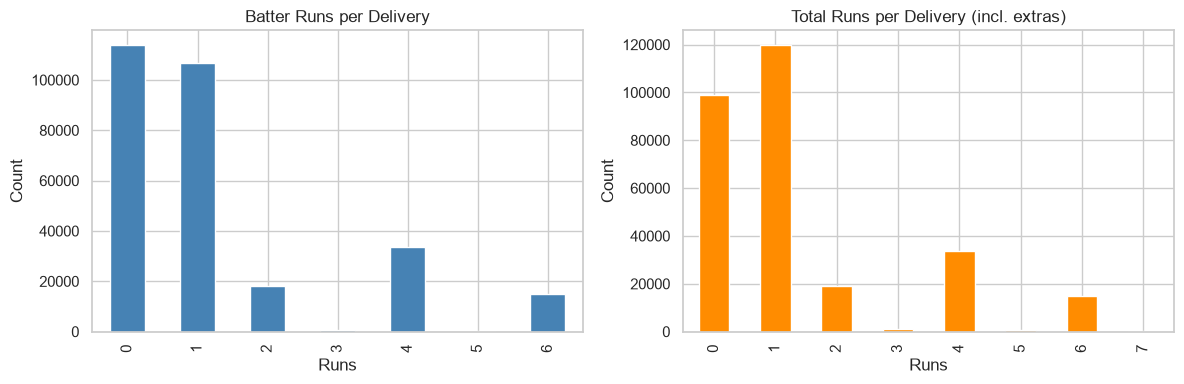

In [60]:
# Run distribution charts
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['batter_runs'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Batter Runs per Delivery')
axes[0].set_xlabel('Runs')
axes[0].set_ylabel('Count')

df['total_runs'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('Total Runs per Delivery (incl. extras)')
axes[1].set_xlabel('Runs')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()


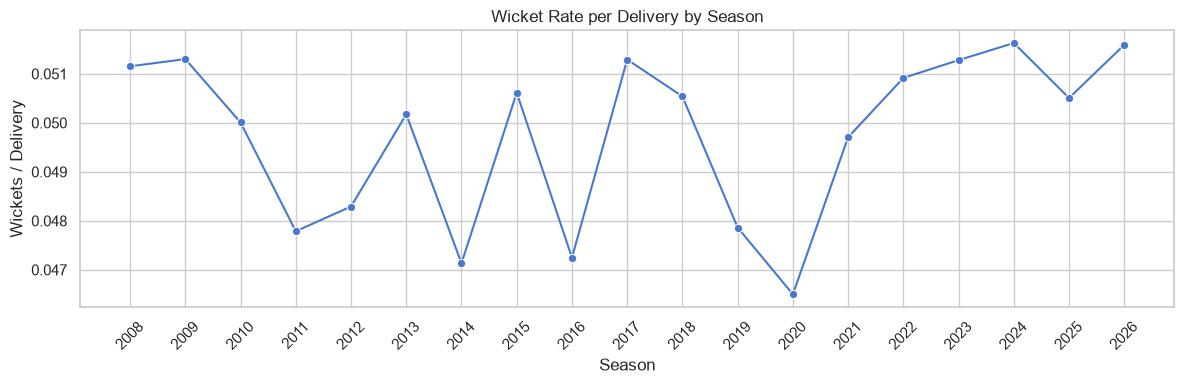

In [61]:
# Wicket rate by season
wicket_rate = df.groupby('season_id')['is_wicket'].mean().reset_index()
wicket_rate.columns = ['season_id', 'wicket_rate']

plt.figure(figsize=(12, 4))
sns.lineplot(data=wicket_rate, x='season_id', y='wicket_rate', marker='o')
plt.title('Wicket Rate per Delivery by Season')
plt.xlabel('Season')
plt.ylabel('Wickets / Delivery')
plt.xticks(wicket_rate['season_id'], rotation=45)
plt.tight_layout()
plt.show()


## 6. Cleaning Steps

In [62]:
# Step 1: Strip whitespace from player name columns
name_cols = ['batter', 'bowler', 'non_striker', 'player_out']
for col in name_cols:
    mask = df[col].notna() & (df[col] != df[col].str.strip())
    if mask.sum() > 0:
        df[col] = df[col].str.strip()
        print(f'{col}: stripped {mask.sum()} padded values')
    else:
        print(f'{col}: clean')


batter: clean
bowler: clean
non_striker: clean
player_out: clean


In [63]:
# Step 2: Strip whitespace from categorical text columns
cat_cols = ['batsman_type', 'bowler_type', 'wicket_kind']
for col in cat_cols:
    mask = df[col].notna() & (df[col] != df[col].str.strip())
    if mask.sum() > 0:
        df[col] = df[col].str.strip()
        print(f'{col}: stripped {mask.sum()} padded values')
    else:
        print(f'{col}: clean')


batsman_type: clean
bowler_type: stripped 8 padded values
wicket_kind: clean


## 7. Final Validation

In [64]:
print(f'Original: {df_raw.shape}')
print(f'Cleaned:  {df.shape}')
print(f'Duplicate rows: {df.duplicated().sum()}')

remaining = df.isnull().sum()
print('\nRemaining nulls:')
print(remaining[remaining > 0])


Original: (288226, 30)
Cleaned:  (288226, 30)
Duplicate rows: 0

Remaining nulls:
batsman_type            239
bowler_type             339
player_out           273886
fielders_involved    273886
wicket_kind          273886
dtype: int64


In [65]:
# Structural alignment check
print('player_out nulls aligned with is_wicket=False:',
      (df['player_out'].isnull() == (df['is_wicket'] == False)).all())

# Numeric ranges unchanged
for col in ['batter_runs', 'extras', 'total_runs']:
    print(f'{col}: [{df[col].min()}, {df[col].max()}]')


player_out nulls aligned with is_wicket=False: True
batter_runs: [0, 6]
extras: [0, 7]
total_runs: [0, 7]


## 8. EDA Findings Summary

| Item | Detail |
|---|---|
| **Rows / Columns** | 288,226 deliveries x 30 columns |
| **Seasons** | 2008 to 2026 (19 seasons) |
| **Exact duplicates** | 0 |
| **Run totals** | `batter_runs + extras = total_runs` confirmed; extras breakdown sums correctly |
| **Negative run values** | None found |
| **ball_number > 5** | Legitimate — occurs only on wides and no-balls |
| **Innings > 2** | 175 super-over deliveries; all have `is_super_over=True` |
| **Wicket nulls** | `player_out`, `wicket_kind`, `fielders_involved` null exactly on non-wicket rows |
| **batsman_type / bowler_type** | ~240–340 nulls retained; cannot impute without joining player table |
| **Cleaning applied** | Whitespace stripping on player name and categorical columns |
| **Fitness for SQL modelling** | Strong — one row per delivery, numeric FKs, clean Boolean flags |

## 9. Export the Cleaned CSV

After the cleaning and final validation steps, export the cleaned dataframe `df` to a CSV file. The export does not include the pandas index, so it will not create an unnecessary index column. The output is written to the notebook's current working directory unless you specify a different path.

In [66]:
from pathlib import Path

OUTPUT_DIR = Path("../../data/cleaned")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PATH = OUTPUT_DIR / "ball_by_ball_data_clean.csv"

df.to_csv(OUTPUT_PATH, index=False, encoding="utf-8")

print(f"Cleaned CSV exported to: {OUTPUT_PATH.resolve()}")
print(f"Rows exported: {len(df):,}")
print(f"Columns exported: {df.shape[1]}")
print(f"File size: {OUTPUT_PATH.stat().st_size / (1024**2):.2f} MB")

Cleaned CSV exported to: C:\Users\Bhuvan\Desktop\IPL DATA\data\cleaned\ball_by_ball_data_clean.csv
Rows exported: 288,226
Columns exported: 30
File size: 42.14 MB


In [67]:
# Re-open the exported file to confirm it can be loaded and its structure is preserved.
df_export_check = pd.read_csv(OUTPUT_PATH)

assert df_export_check.shape == df.shape, (df_export_check.shape, df.shape)
assert df_export_check.columns.tolist() == df.columns.tolist()

print("Export verification passed.")
print("Exported shape:", df_export_check.shape)
display(df_export_check.head(3))

Export verification passed.
Exported shape: (288226, 30)


,season_id,match_id,batter,bowler,non_striker,team_batting,team_bowling,over_number,ball_number,batter_runs,extras,total_runs,batsman_type,bowler_type,player_out,fielders_involved,is_wicket,is_wide_ball,is_no_ball,is_leg_bye,is_bye,is_penalty,wide_ball_runs,no_ball_runs,leg_bye_runs,bye_runs,penalty_runs,wicket_kind,is_super_over,innings
0,2008,335982,SC Ganguly,P Kumar,BB McCullum,6,1,0,0,0,1,1,Left hand Bat,Right arm Medium,NaN,NaN,False,False,False,True,False,False,0,0,1,0,0,NaN,False,1
1,2008,335982,BB McCullum,P Kumar,SC Ganguly,6,1,0,1,0,0,0,Right hand Bat,Right arm Medium,NaN,NaN,False,False,False,False,False,False,0,0,0,0,0,NaN,False,1
2,2008,335982,BB McCullum,P Kumar,SC Ganguly,6,1,0,2,0,1,1,Right hand Bat,Right arm Medium,NaN,NaN,False,True,False,False,False,False,1,0,0,0,0,NaN,False,1
